# Import

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# Graph question 1

### Which item do customers put in their cart first

##### Preparation des datas

In [3]:


# on va prendre tt les items, on va faire une moyenne de leurs position dans le cart, et on va ensuite afficher pour chaque item ca position
# dans le cart dans l'ordre croissant

CSV_untouch = pd.read_csv('CSV_Cleaned.csv')

# on fait ici un groupby pour permettre de regroupper touts nos achats de produits sous les meme produits et de permettre 
# d'avoir leurs moyenne d'emplacement dans le panier d'un client
CSV_Clean = CSV_untouch.groupby(
    ["product_name"]
).agg(
    {
        "add_to_cart_order": "mean"
    }
)

# on retirer les index
CSV_Clean = CSV_Clean.reset_index()

##### Code graphique

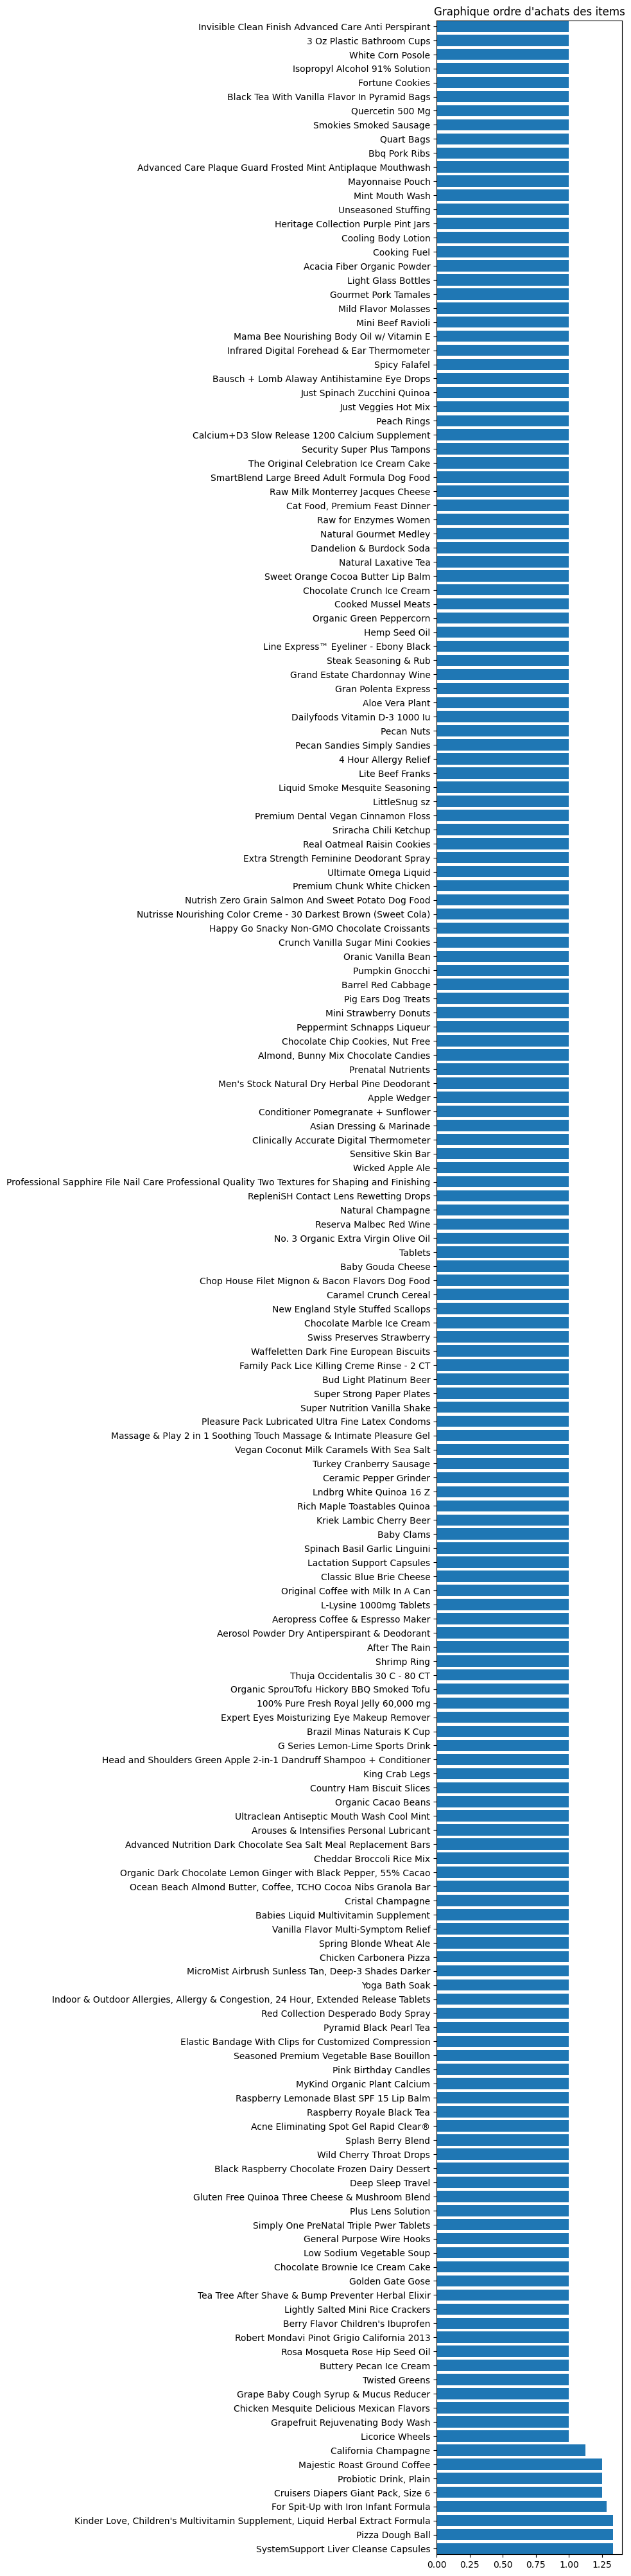

In [4]:
CSV_Clean = CSV_Clean.sort_values(by=["add_to_cart_order"])
# on prend ici les 180 premieres valeurs, car cela permet d'avoior entierement la liste des premieres valeurs
DF = CSV_Clean.head(180)

# on defini nos column
x = DF['product_name']
y = DF['add_to_cart_order']

# on met ici un graphique en hauteur pour avoir plus de visibilite
fig, ax = plt.subplots(figsize=(10, 40))

# on met ceci ici pour que la premiere valeur vient bien tout en haut du graphique sans espace blanc avec tight=True
ax.autoscale(enable=True, axis='y', tight=True)

# c'est la variante de .bar mais ici pour les valeur verticale
ax.barh(x, y)

#on inverse les axe pour avoir la + petite valeur en premiere
ax.invert_yaxis()

# permet de bien mettre tout les noms correctement, les format, retire les espaces inutiles, etc
plt.tight_layout()
plt.title("Graphique ordre d'achats des items")

# on save l'image
plt.savefig('Graphique_Img/Graph_First_item_cart.png')

plt.show()

# Graph question 2

### Which aisle and departement have the most (less) preoducts

##### Preparation des datas

In [5]:
listeaisle = {}

# On fait un boucle qui parcour tout DF et on ajoute chaque nouvelle allée en clé si elle n'existe pas et on augmente sa valeur qui 
# correspond au nombre de fois ou cette allée apparait dans le CSV
for k in CSV_untouch["aisle"]:
    if k not in listeaisle:
         listeaisle[k] = 1
    else:
        listeaisle[k] += 1

##### Code graphique

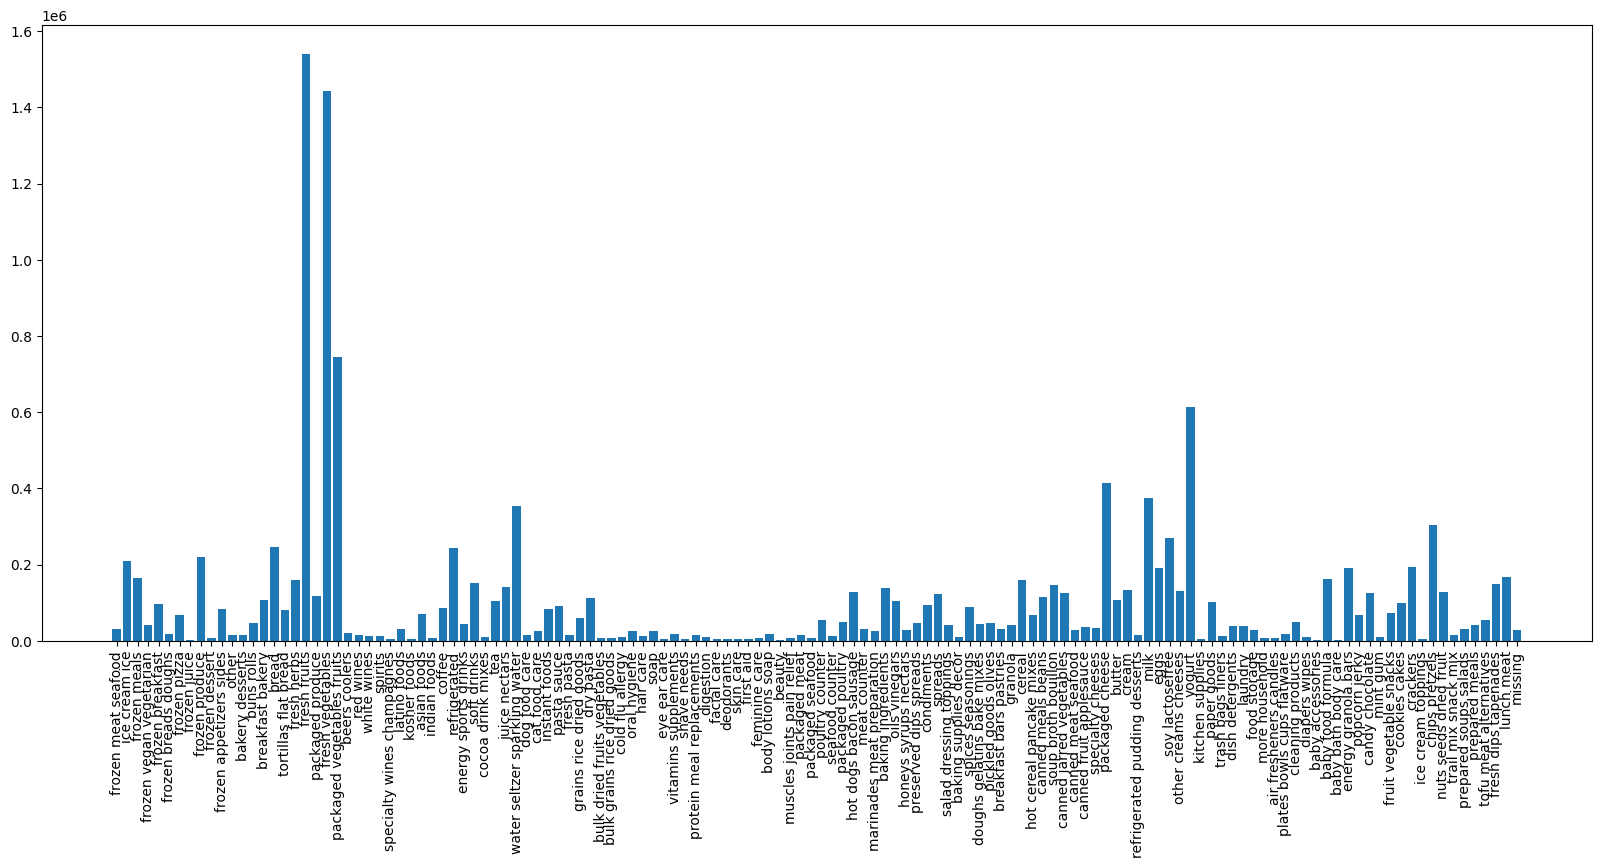

In [6]:
x = listeaisle.keys()
y = listeaisle.values()
plt.figure(figsize=(20, 8))
plt.bar(x, y)
plt.tick_params(axis='x', labelrotation=90)

plt.show()

##### Preparation des datas

In [7]:
listedep = {}

# On fait un boucle qui parcour tout DF et on ajoute chaque nouveau département en clé si elle n'existe pas et on augmente sa valeur qui 
# correspond au nombre de fois ou ce département apparait dans le CSV
for k in CSV_untouch["department"]:
    if k not in listedep:
         listedep[k] = 1
    else:
        listedep[k] += 1

##### Code graphique

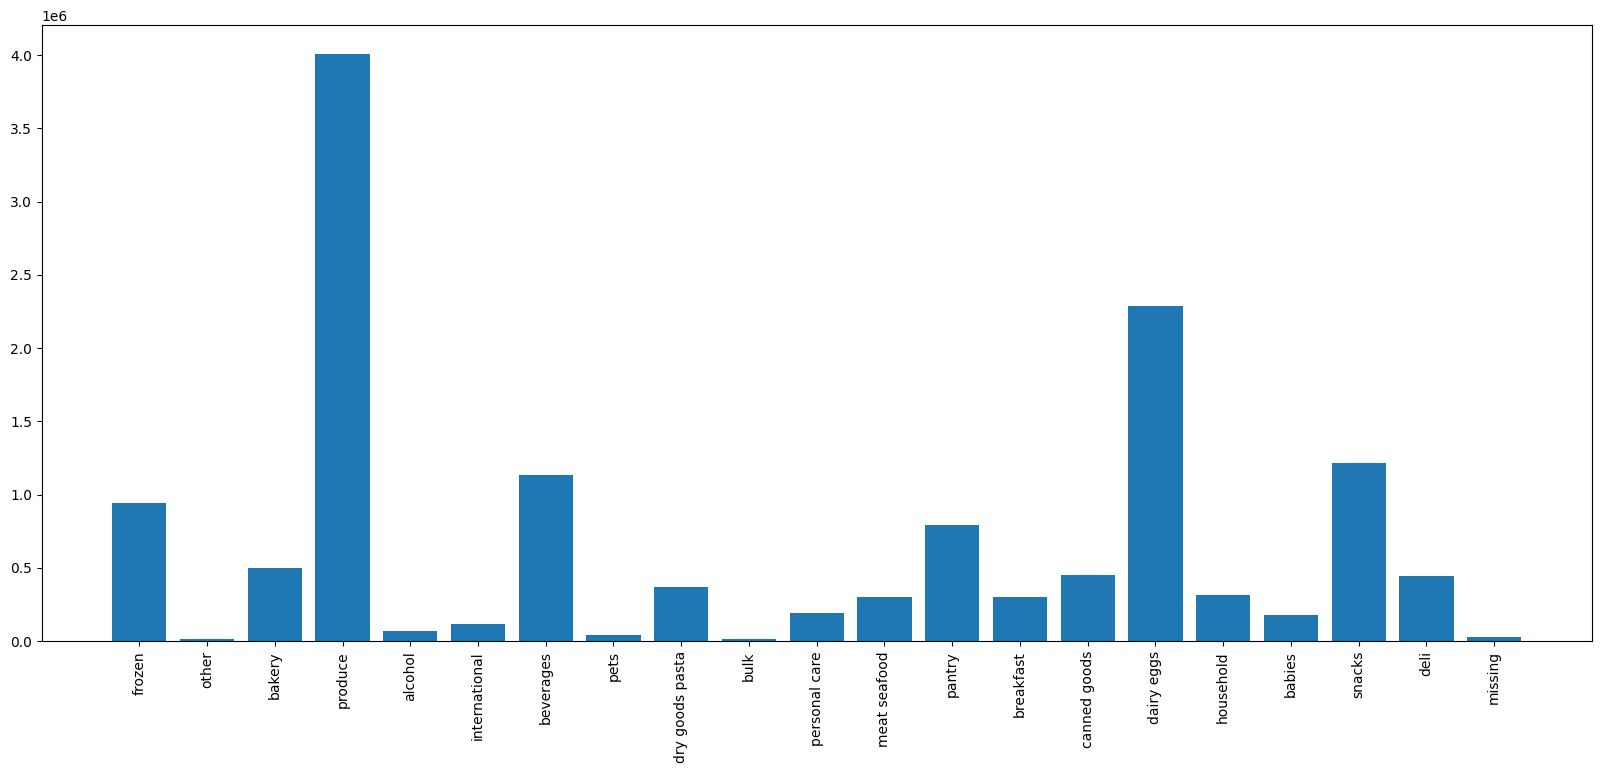

In [8]:
x = listedep.keys()
y = listedep.values()
plt.figure(figsize=(20, 8))
plt.bar(x, y)
plt.tick_params(axis='x', labelrotation=90)

plt.show()

# Graph question 3

### Which product have the heights probability of being reordered

##### Preparation des datas

In [9]:
CSV_Clean = CSV_untouch.groupby("product_name")["reordered"].mean()
top_1 = CSV_Clean.sort_values(ascending=False).head(1)
print(top_1.keys())
CSV_Clean = CSV_Clean.sort_values(ascending=False).head(100)


Index(['Skin Renew Miracle Skin Perfector BB Cream: Daily Anti-Aging, Light/Medium'], dtype='object', name='product_name')


##### Code graphique

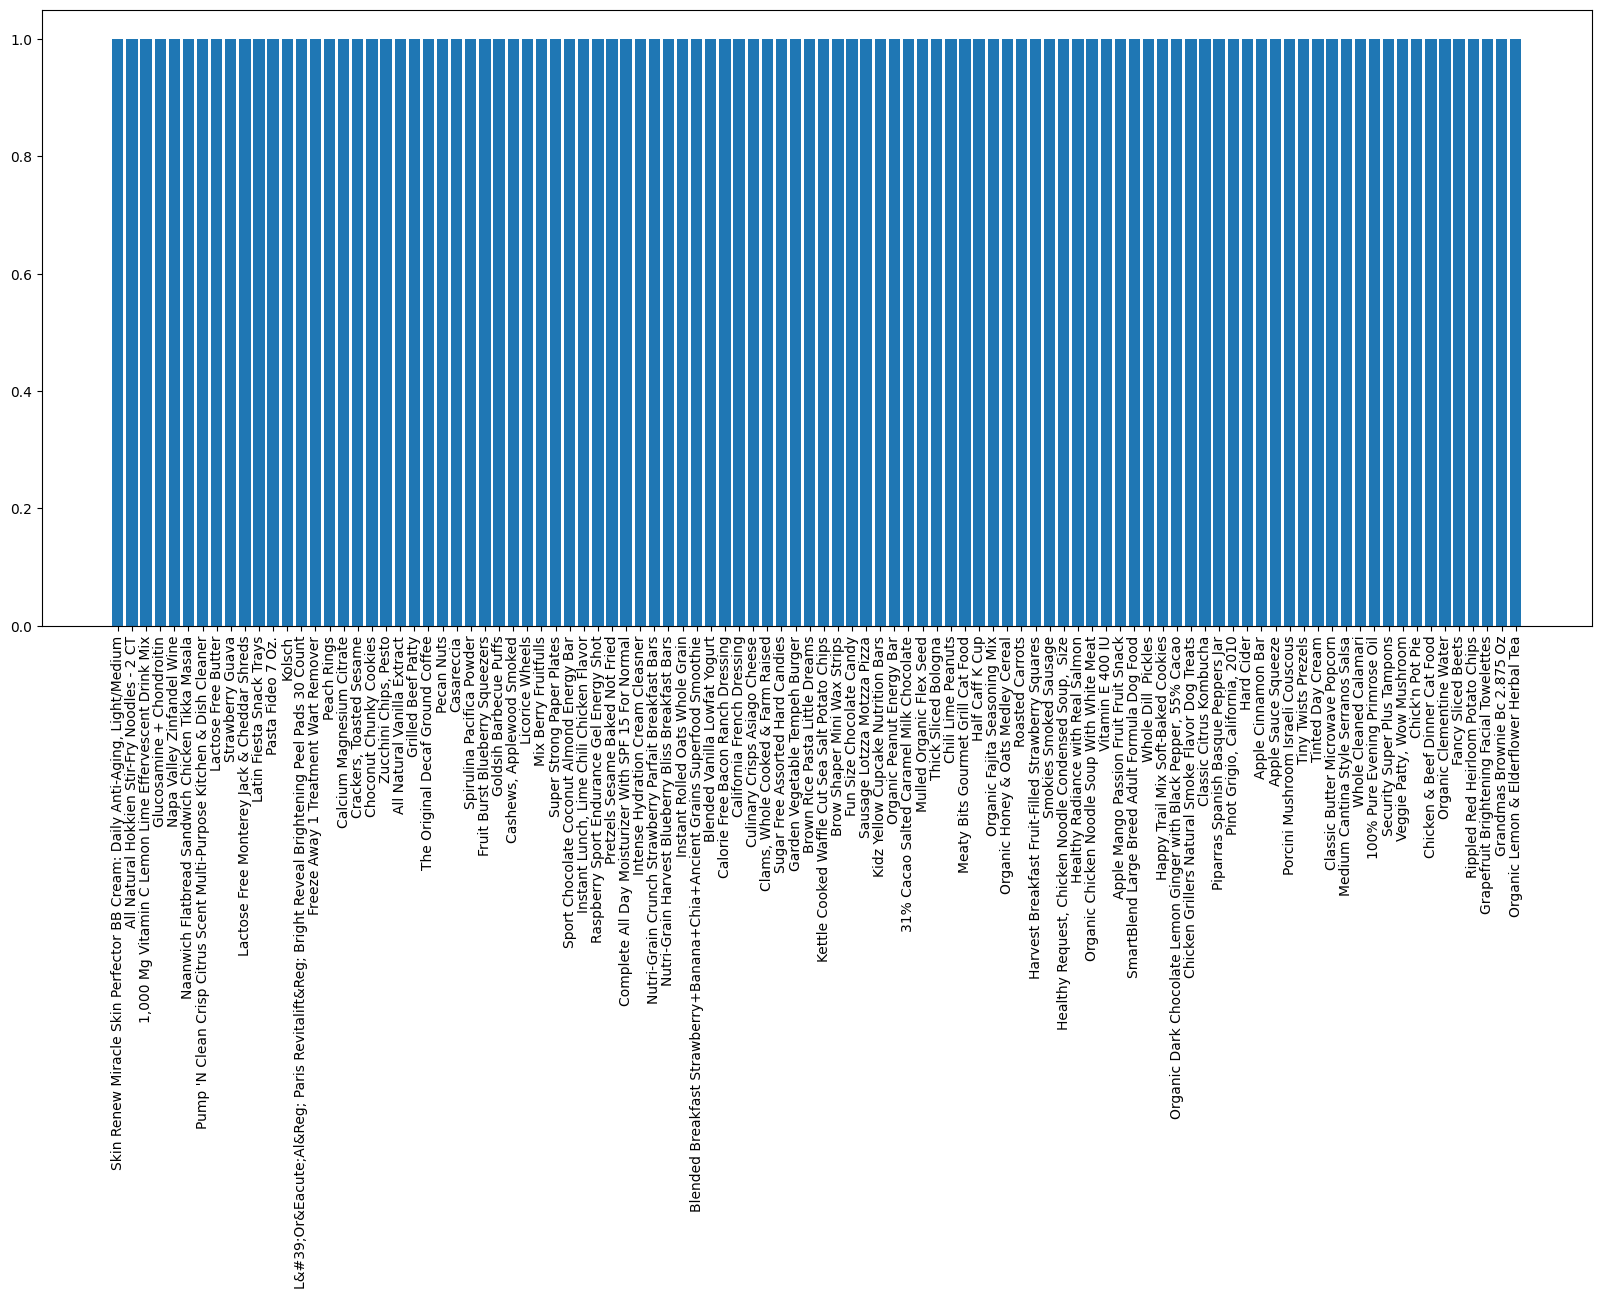

In [10]:
x = CSV_Clean.keys()
y = CSV_Clean.values
plt.figure(figsize=(20, 8))
plt.bar(x, y)
plt.tick_params(axis='x', labelrotation=90)
plt.show()

# Graph question 4

### When and how do custormers usually order

##### Preparation des datas

In [11]:
#               =========================================================
#                 Ici on va essayer de dessiner le "When" de la question
#               =========================================================


# On récupère dans la variable DF la colonne "order_hour_of_day" dans le CSV, et on round les heures pour avoir des heures pleines.
DF = round(CSV_untouch["order_hour_of_day"], 0)

listeheure = {}

# On fait un boucle qui parcour tout DF et on ajoute chaque nouvelle heure en clé si elle n'existe pas et on augmente sa valeur qui 
# correspond au nombre de fois ou cette heure apparait dans le CSV
for k in DF:
    if k not in listeheure:
         listeheure[k] = 1
    else:
        listeheure[k] += 1

##### Code graphique

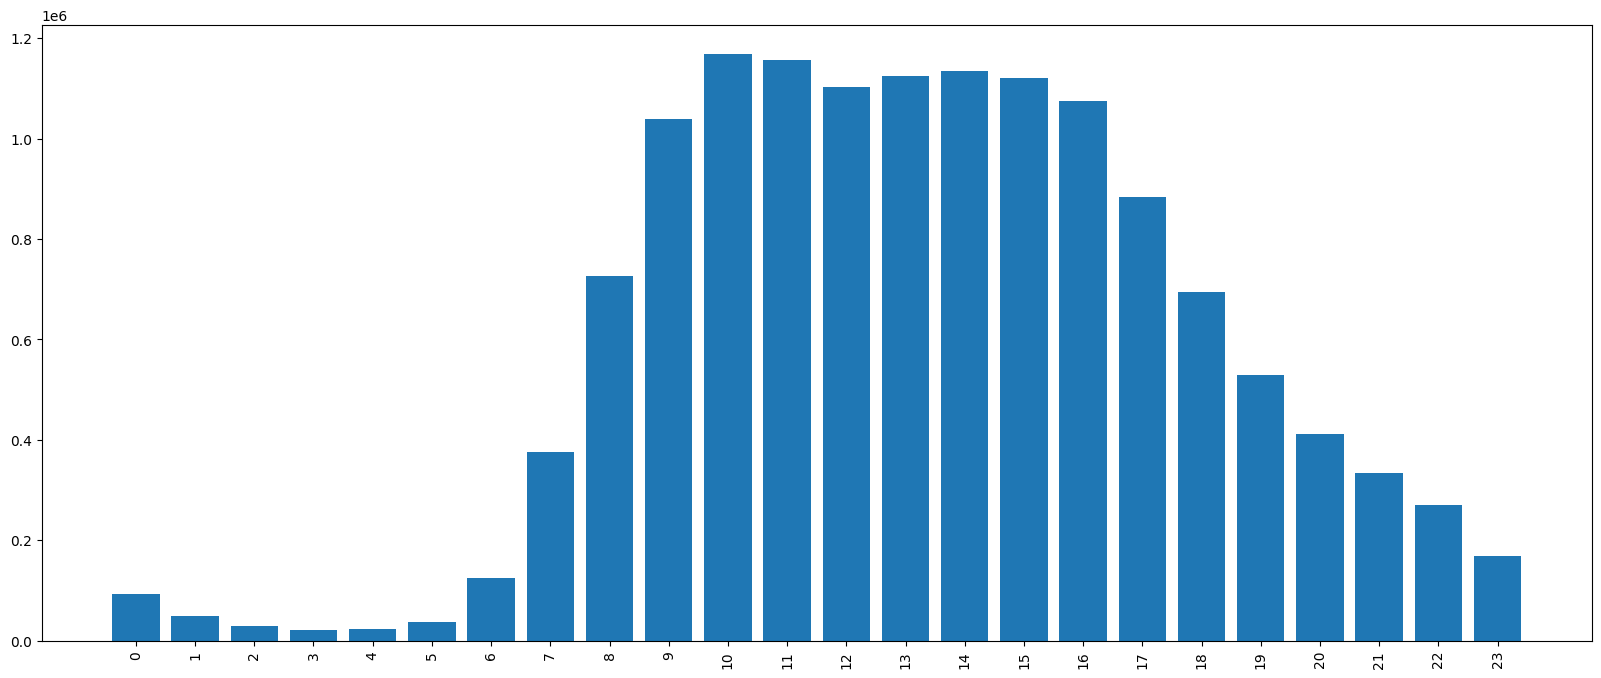

In [12]:
x = listeheure.keys()
y = listeheure.values()
plt.figure(figsize=(20, 8))
plt.bar(x, y)
plt.tick_params(axis='x', labelrotation=90)
ax = plt.gca()
ax.set_xticks(range(0, 24, 1))


plt.show()

#### Preparation des datas

In [13]:
#               =========================================================
#                          Et ici on va s'occuper du "How"
#               =========================================================


DF = round(CSV_untouch["days_since_prior_order"], 0)
print(len(DF))

listejour = {}

# On fait un boucle qui parcour tout DF, et on ajoute chaque nouvelle durée de temps en clé si elle n'existe pas, et on augmente sa valeur qui 
# correspond au nombre de fois ou cette durée apparait dans le CSV
for k in DF:
    if k not in listejour:
        listejour[k] = 1
    else:
        listejour[k] += 1

KeyError: 'days_since_prior_order'

##### Code graphique

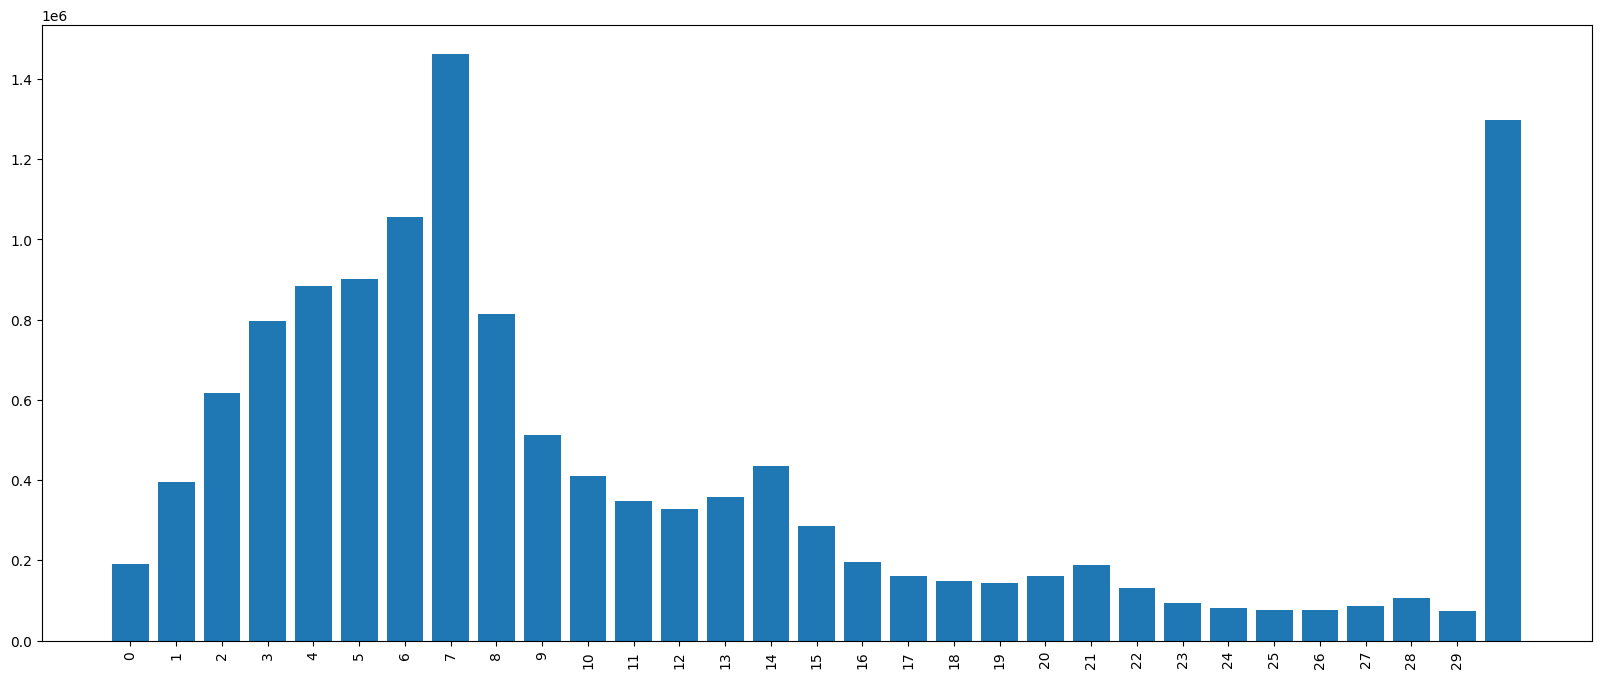

In [ ]:
x = listejour.keys()
y = listejour.values()
plt.figure(figsize=(20, 8))
plt.bar(x, y)
plt.tick_params(axis='x', labelrotation=90)
ax = plt.gca()
ax.set_xticks(range(0, 30, 1))

plt.show()

# Question graphique 5

### Quel est l'horaire ou il y a le plus d'achat de nourriture

#### Preparation des datas

In [ ]:
# on va prendre suppriner les items qui ne sont pas de la nourriture.
CSV_untouch = pd.read_csv('CSV_Cleaned.csv')

# on defini les departement qui ne sont pas des aliments
Bad_DEPARTEMENT = ['other', 'pets', 'personal care', 'house hold']
# on va drop les row ou nous avons des departement qui ne sont pas correcte donc, les departements qui sont dans notre liste Bad_DEPARTEMENT
CSV_untouch = CSV_untouch.drop(CSV_untouch[CSV_untouch.department.isin(Bad_DEPARTEMENT)].index)


# on va faire un groupby, on va regrouper les user_id avec les heures de la journee
CSV_Clean = CSV_untouch.groupby(
    ["user_id"]
).agg(
    {
        "order_hour_of_day": "mean"
    }
)

# on va ici round car les heures ne sont pas pleine mais nous nous ne voulons que les heures pleines
DF = round(CSV_Clean, 0)

##### Code graphiqueµ

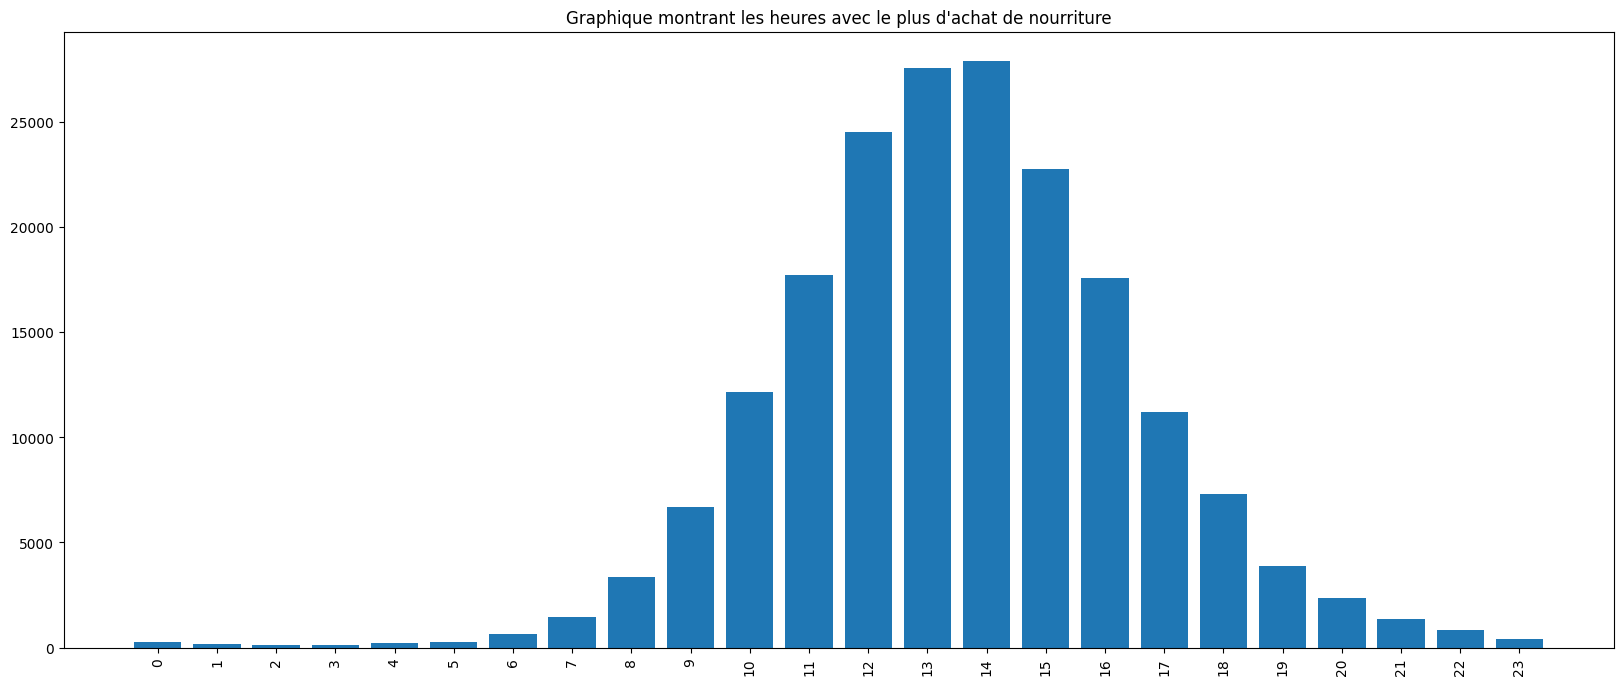

In [ ]:
#print(len(DF))
# on defini ici notre dictionnaire d'heure
listeheure = {}

# on passe dans toute les heures de notre journee pour chaque row, et on va ajouter + a la notre heure, exemple {14: 5}, cela veut dire que pour la valeur 14h, nous la'vions deja eu 5 fois, on va donc ajouter +1 si on retombe dessus
for k in DF["order_hour_of_day"]:
    if k not in listeheure:
        listeheure[k] = 1
    else:
        listeheure[k] += 1

# on defini nos x et y avec le dictionnaire
x = listeheure.keys()
y = listeheure.values()

#on defini la taille du graph
plt.figure(figsize=(20, 8))
plt.bar(x, y)

# on rotate les label x
plt.tick_params(axis='x', labelrotation=90)

# permnet de definir la zone des axes
ax = plt.gca()

# defini un range
ax.set_xticks(range(0, 24, 1))
plt.title("Graphique montrant les heures avec le plus d'achat de nourriture")

# on save
plt.savefig('Graphique_Img/Graph+_buy_food')
plt.show()

# Graphique question 6

### Moyenne du nombre de jour passé depuis le précédent achat

#### Preparation des datas

In [ ]:
CSV_Clean = CSV_untouch.groupby(
    ["user_id"]
).agg(
    {
        "days_since_prior_order": "mean"   
    }
)
CSV_Clean = CSV_Clean.reset_index()

DF = round(CSV_Clean, 0)

listejour = {}

# On fait un boucle qui parcour tout DF, et on ajoute chaque nouvelle durée de temps en clé si elle n'existe pas, et on augmente sa valeur qui 
# correspond au nombre de fois ou cette durée apparait dans le CSV
for k in DF["days_since_prior_order"]:
    if k not in listejour:
        listejour[k] = 1
    else:
        listejour[k] += 1

##### Code graphique

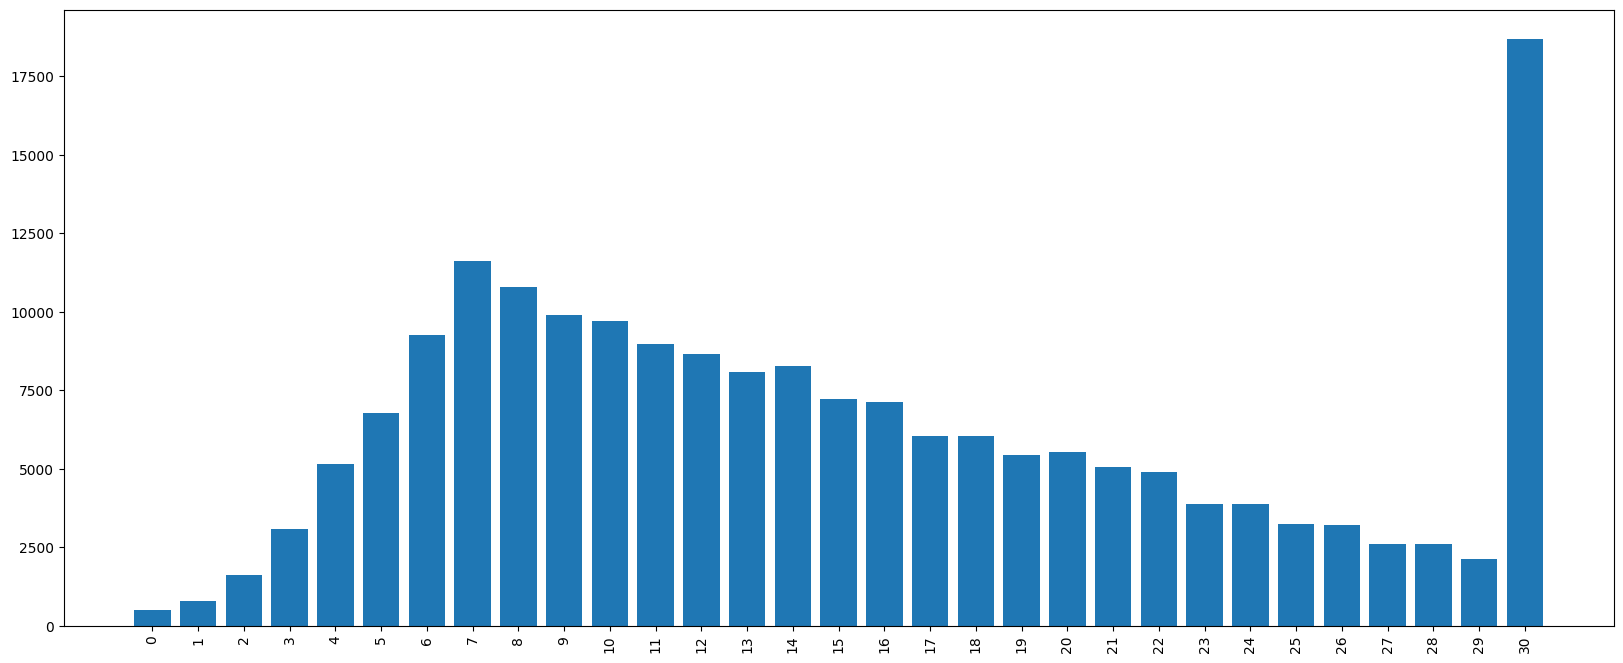

In [ ]:
x = listejour.keys()
y = listejour.values()
plt.figure(figsize=(20, 8))
plt.bar(x, y)
plt.tick_params(axis='x', labelrotation=90)
ax = plt.gca()
ax.set_xticks(range(0, 31, 1))

plt.show()

##### Moyenne de tous les jours

In [ ]:
print (DF["days_since_prior_order"].mean())

15.073838102579431


# Question graphique 7

### Pourcentage de meme articles acheter quand un client va racheter dans le magasin

##### Preparation des datas

In [ ]:
# on va faire un groupy pour chaque user_id
CSV_Clean = CSV_untouch.groupby("user_id").agg(
    # lst_unique=("product_name", "unique"),  # on va prendre la liste des objets achete sans doublon
    nbr_unique=("product_name", "nunique"),    # on va prendre la taille de la liste d'objet unique
    total_achat=("product_name", "count")     # on va prendre le nombre total d'objets/ items acheter y compris les doublons
)

# on connait maintenant le nombre d'items acheter et le nombre d'items acheter qui sont unique, par consequent le nombre d'items racheter c'est le nombre total - le nombre unique
# on va donc calculer mathematiquement en faisant :
# (Total des achats - items uniques) = Nombre d'itenms racheter
# Pourcentage -> = (Nombre de rachats / Total des achats) * 100
DataFrameRachat = pd.DataFrame()
DataFrameRachat['tauxrachat%'] = ((CSV_Clean['total_achat'] - CSV_Clean['nbr_unique']) / CSV_Clean['total_achat']) * 100



Pourcentage_rachat = DataFrameRachat['tauxrachat%'].mean()

##### Code graphique

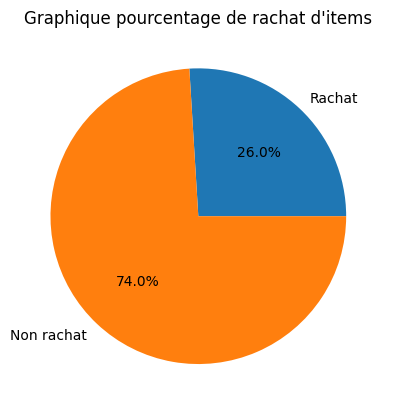

In [ ]:
labels = 'Rachat', 'Non rachat'

# on prend notre % total calculer au dessus
sizes = [Pourcentage_rachat, 100-Pourcentage_rachat]

fig, ax = plt.subplots()
# on fait un autopct pour permettre d'afficher les pourcentage automatiquement sur le graph
ax.pie(sizes, labels=labels, autopct='%1.1f%%')

plt.title("Graphique pourcentage de rachat d'items")


# on save
plt.savefig('Graphique_Img/Pourcentage_Rachat')

# Graphique question 8

### Quels produits sont frequement acheter ensemble

##### Preparation des datas

In [ ]:
# on va ici trier les valeurs de order_id et add_to_cart_order pour que tout soient bien ensemble
df = CSV_untouch.sort_values(['order_id', 'add_to_cart_order'])

# le produit suivant on prend juste notre row avec le product_name et on fait um .shift(-1) pour remonter prendre celui d'apres
df['produit_suivant'] = df['product_name'].shift(-1)

# on va ici verifier que la ligne de notre order_id soit bien la meme que la ligne suivante pour ne pas prendre des items d'une autres perssonnes
df_seq = df[df['order_id'] == df['order_id'].shift(-1)]

# on fait ici la liste des X duos de produit les plus pris ensemble avec un value_counts, on compte juste combien de fois ils sont acheter ensemble
Duos = df_seq.value_counts(['product_name', 'produit_suivant']).head(50)

##### Code graphique